In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

# Manually exploring the data and creating a classification function

In [6]:
# CKD: chronic kidney disease
ckd = Table.read_table('data/ckd.csv').relabeled('Blood Glucose Random', 'Glucose')
ckd.sample(5)

Age,Blood Pressure,Specific Gravity,Albumin,Sugar,Red Blood Cells,Pus Cell,Pus Cell clumps,Bacteria,Glucose,Blood Urea,Serum Creatinine,Sodium,Potassium,Hemoglobin,Packed Cell Volume,White Blood Cell Count,Red Blood Cell Count,Hypertension,Diabetes Mellitus,Coronary Artery Disease,Appetite,Pedal Edema,Anemia,Class
58,70,1.025,0,0,normal,normal,notpresent,notpresent,88,16,1.1,147,3.5,16.4,53,9100,5.2,no,no,no,good,no,no,0
56,80,1.025,0,0,normal,normal,notpresent,notpresent,139,15,1.2,135,5,14.8,42,5600,5.5,no,no,no,good,no,no,0
71,70,1.01,3,0,normal,abnormal,present,present,219,82,3.6,133,4.4,10.4,33,5600,3.6,yes,yes,yes,good,no,no,1
17,60,1.025,0,0,normal,normal,notpresent,notpresent,114,50,1,135,4.9,14.2,51,7200,5.9,no,no,no,good,no,no,0
33,80,1.025,0,0,normal,normal,notpresent,notpresent,89,19,1.1,144,5,15,40,10300,4.8,no,no,no,good,no,no,0


In [8]:
shuffled_ckd = ckd.sample(with_replacement=False)
shuffled_ckd.num_rows

158

In [12]:
training_set = shuffled_ckd.take(np.arange(100))
test_set = shuffled_ckd.take(np.arange(100, 158))

In [13]:
training_set

Age,Blood Pressure,Specific Gravity,Albumin,Sugar,Red Blood Cells,Pus Cell,Pus Cell clumps,Bacteria,Glucose,Blood Urea,Serum Creatinine,Sodium,Potassium,Hemoglobin,Packed Cell Volume,White Blood Cell Count,Red Blood Cell Count,Hypertension,Diabetes Mellitus,Coronary Artery Disease,Appetite,Pedal Edema,Anemia,Class
46,70,1.025,0,0,normal,normal,notpresent,notpresent,100,47,0.5,142,3.5,16.4,43,5700,6.5,no,no,no,good,no,no,0
68,60,1.025,0,0,normal,normal,notpresent,notpresent,125,41,1.1,139,3.8,17.4,50,6700,6.1,no,no,no,good,no,no,0
46,60,1.02,0,0,normal,normal,notpresent,notpresent,102,27,0.7,142,4.9,13.2,44,11000,5.4,no,no,no,good,no,no,0
22,60,1.025,0,0,normal,normal,notpresent,notpresent,97,18,1.2,138,4.3,13.5,42,7900,6.4,no,no,no,good,no,no,0
62,70,1.025,3,0,normal,abnormal,notpresent,notpresent,122,42,1.7,136,4.7,12.6,39,7900,3.9,yes,yes,no,good,no,no,1
57,60,1.02,0,0,normal,normal,notpresent,notpresent,132,18,1.1,150,4.7,15.4,42,11000,4.5,no,no,no,good,no,no,0
73,60,1.02,0,0,normal,normal,notpresent,notpresent,127,48,0.5,150,3.5,15.1,52,11000,4.7,no,no,no,good,no,no,0
42,80,1.02,0,0,normal,normal,notpresent,notpresent,98,20,0.5,140,3.5,13.9,44,8400,5.5,no,no,no,good,no,no,0
71,70,1.02,0,0,normal,normal,notpresent,notpresent,81,18,0.8,145,5,14.7,44,9800,6,no,no,no,good,no,no,0
58,70,1.025,0,0,normal,normal,notpresent,notpresent,88,16,1.1,147,3.5,16.4,53,9100,5.2,no,no,no,good,no,no,0


In [14]:
training_set.group('Class')

Class,count
0,74
1,26


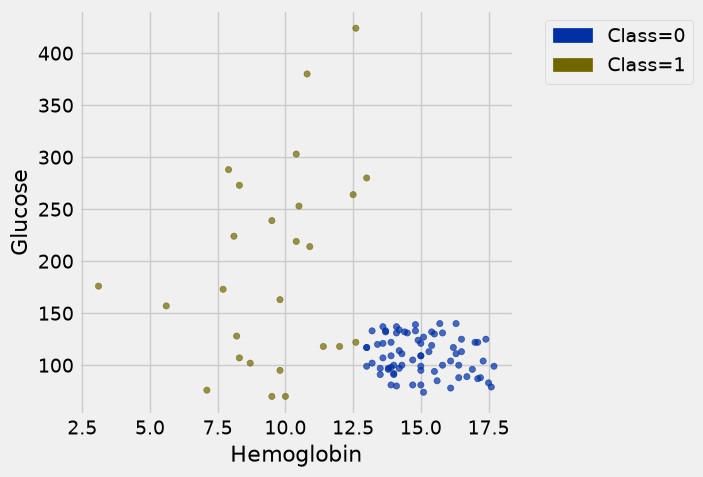

In [17]:
training_set.scatter('Hemoglobin', 'Glucose', group='Class')

In [18]:
min_hemoglobin_for_0 = training_set.where('Class', 0).column('Hemoglobin').min()
max_glucose_for_0 = training_set.where('Class', 0).column('Glucose').max()
min_hemoglobin_for_0, max_glucose_for_0

(13.0, 140)